# Map Plot Analyses
Analyses in support spatially-distributed figures (e.g., Figure 2) of the corresponding PyGEM-WBM study

In [1]:
import os

import cartopy
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib as mpl
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.path as mpath
import matplotlib.patches as patches
from matplotlib.patches import Patch
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FixedLocator, LogLocator, NullFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
from rasterstats import zonal_stats
import rioxarray
import rasterio
from scipy.ndimage import uniform_filter
from scipy.spatial import ConvexHull
from shapely.geometry import Point
import xarray as xr

### Set SSP for all plots

In [2]:
ssp = 'ssp585'

In [3]:
main_directory = os.getcwd()

gcm_names = ['BCC-CSM2-MR', 'CESM2', 'CESM2-WACCM', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-f3-L', 
             'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'MPI-ESM1-2-HR', 'MRI-ESM2-0', 'NorESM2-MM']

# Plotting details
ssp_name_dict = {'126':'SSP1-2.6',
                 '245':'SSP2-4.5',
                 '370':'SSP3-7.0',
                 '585':'SSP5-8.5',
                 'ssp126':'SSP1-2.6',
                 'ssp245':'SSP2-4.5',
                 'ssp370':'SSP3-7.0',
                 'ssp585':'SSP5-8.5',
                }
ssp_colordict = {'119':'#081d58', '126':'#1d91c0', '245':'#7fcdbb', '370':'#F47A20', '585':'#ED2024',
                'ssp119':'#081d58', 'ssp126':'#1d91c0', 'ssp245':'#7fcdbb', 'ssp370':'#F47A20', 'ssp585':'#ED2024'}

paper_fig_fp = 'figures_paper/'
if not os.path.exists(paper_fig_fp):
    os.makedirs(paper_fig_fp)

# Map Figure

## Discharge Data to Plot

In [4]:
qmax_fp = 'wbm_data/discharge_month_max/'

# Historical 
qmax_fn = 'historical_max_discharge_m3s_pg_frac.nc'
ds_qmax = xr.open_dataset(qmax_fp + qmax_fn)
qmax = ds_qmax['max_monthly_frac'].values

qmax_2006_2015 = np.mean(qmax[-10:,:,:], axis=0)

# Future
qmax_gcms = None
for ngcm, gcm_name in enumerate(gcm_names):

    qmax_fn = gcm_name + '_' + ssp + '_max_discharge_m3s_pg_frac.nc'

    ds_qmax = xr.open_dataset(qmax_fp + qmax_fn)

    qmax = ds_qmax['max_monthly_frac'].values

    if qmax_gcms is None:
        qmax_gcms = qmax[np.newaxis,:,:,:]
    else:
        qmax_gcms = np.concatenate((qmax_gcms, qmax[np.newaxis,:,:,:]), axis=0)

# # 2016-2025
# qmax_gcms_2016_2025_mean = np.nanmean(qmax_gcms[:,0:10,:,:], axis=1)
# qmax_multigcm_med_2016_2025 = np.nanmedian(qmax_gcms_2016_2025_mean, axis=0)

# 2090-2100
qmax_gcms_2090_2099_mean = np.nanmean(qmax_gcms[:,-10:,:,:], axis=1)
qmax_multigcm_med_2090_2099 = np.nanmedian(qmax_gcms_2090_2099_mean, axis=0)

/var/folders/wz/xj3ys3v57z71zx2d2vhczznw0000gn/T/ipykernel_44420/1079406855.py:30: RuntimeWarning: Mean of empty slice
  qmax_gcms_2090_2099_mean = np.nanmean(qmax_gcms[:,-10:,:,:], axis=1)
/var/folders/wz/xj3ys3v57z71zx2d2vhczznw0000gn/T/ipykernel_44420/1079406855.py:31: RuntimeWarning: All-NaN slice encountered
  qmax_multigcm_med_2090_2099 = np.nanmedian(qmax_gcms_2090_2099_mean, axis=0)


## Irrigation Data to Plot

In [5]:
irrmax_fp = 'wbm_data/irr_month_max/'

# Historical
irrmax_fn = 'historical_max_GrossIrr_mm_pg_frac.nc'
ds_irrmax = xr.open_dataset(irrmax_fp + irrmax_fn)
irrmax = ds_irrmax['max_monthly_frac'].values

irrmax_2006_2015 = np.mean(irrmax[-10:,:,:], axis=0)


# Future
irrmax_gcms = None
for ngcm, gcm_name in enumerate(gcm_names):

    irrmax_fn = gcm_name + '_' + ssp + '_max_GrossIrr_mm_pg_frac.nc'

    ds_irrmax = xr.open_dataset(irrmax_fp + irrmax_fn)

    irrmax = ds_irrmax['max_monthly_frac'].values
    

    if irrmax_gcms is None:
        irrmax_gcms = irrmax[np.newaxis,:,:,:]
    else:
        irrmax_gcms = np.concatenate((irrmax_gcms, irrmax[np.newaxis,:,:,:]), axis=0)

# # 2016-2025
# irrmax_gcms_2016_2025_mean = np.nanmean(irrmax_gcms[:,0:10,:,:], axis=1)
# irrmax_multigcm_med_2016_2025 = np.nanmedian(irrmax_gcms_2016_2025_mean, axis=0)

# # 2090-2100
irrmax_gcms_2090_2099_mean = np.nanmean(irrmax_gcms[:,-10:,:,:], axis=1)
irrmax_multigcm_med_2090_2099 = np.nanmedian(irrmax_gcms_2090_2099_mean, axis=0)

/var/folders/wz/xj3ys3v57z71zx2d2vhczznw0000gn/T/ipykernel_44420/1716934497.py:32: RuntimeWarning: Mean of empty slice
  irrmax_gcms_2090_2099_mean = np.nanmean(irrmax_gcms[:,-10:,:,:], axis=1)
/var/folders/wz/xj3ys3v57z71zx2d2vhczznw0000gn/T/ipykernel_44420/1716934497.py:33: RuntimeWarning: All-NaN slice encountered
  irrmax_multigcm_med_2090_2099 = np.nanmedian(irrmax_gcms_2090_2099_mean, axis=0)


### Domestic Use & Cities to Plot

#### Cities

In [6]:
city_processed_fp = 'processed_data/cities/'
city_processed_fn = ssp + '_cities_dom_frac_wstats.geojson'

if not os.path.exists(city_processed_fp + city_processed_fn):

    # ----- LOAD CITY DOMESTIC FRACTION DATA FOR HISTORIC AND FUTURE -----
    citymax_fp = 'wbm_data/city_domestic_water/'
    
    # Historical
    citymax_fn_hist = 'historical_city_domestic_pg_max_month_fraction.csv'
    citymax_df_hist = pd.read_csv(citymax_fp + citymax_fn_hist, index_col=0)
    
    # Future
    citymax_fn_ssp = 'city_domestic_pg_max_month_fraction_median_' + ssp + '.csv'
    citymax_df_ssp = pd.read_csv(citymax_fp + citymax_fn_ssp, index_col=0)
    
    # Merge together
    citymax_df = pd.merge(citymax_df_hist, citymax_df_ssp, on=['FID', 'CITY_NAME', 'CNTRY_NAME'])
    citymax_df['max_2006_2099'] = citymax_df.loc[:, '2006':'2099'].max(axis=1)
    citymax_df['2006_2015_mean'] = citymax_df[[str(x) for x in range(2006,2016)]].mean(axis=1)
    citymax_df['2090_2099_mean'] = citymax_df[[str(x) for x in range(2090,2100)]].mean(axis=1)
    
    citymax_df_subset = citymax_df[citymax_df['max_2006_2099'] > 0.1].copy()
    citymax_df_subset.reset_index(inplace=True, drop=True)
    
    citymax_df_subset['name'] = ([citymax_df_subset.loc[x, 'CITY_NAME'] + ', ' + citymax_df_subset.loc[x, 'CNTRY_NAME'] 
                                  for x in citymax_df_subset.index.values])

    # ----- ADD POPULATION DATA -----
    citypop_fp = 'wbm_data/city_domestic_water/World_Cities/'
    citypop_fn = 'World_Cities.shp'
    
    cities_pop_gdf = gpd.read_file(citypop_fp + citypop_fn)
    
    pop_threshold = 100000
    
    # Function to find population
    def get_population(row):
        # Filter the cities_pop_gdf for matching CITY_NAME and CNTRY_NAME
        match = cities_pop_gdf[
            (cities_pop_gdf['CITY_NAME'] == row['CITY_NAME']) &
            (cities_pop_gdf['CNTRY_NAME'] == row['CNTRY_NAME'])
        ]
        
        # If a match is found, return the population; otherwise, return None
        if not match.empty:
            return match['POP'].values[0]
        return None
    
    # Apply the function to each row and create a new column for population
    citymax_df_subset['POP'] = citymax_df_subset.apply(get_population, axis=1)
    citymax_df_subset = citymax_df_subset[citymax_df_subset['POP'] > pop_threshold].copy()

    # ----- ADD LATITUDE & LONGITUDE -----
    # ChatGPT lat/lons added
    cities_gdf = gpd.read_file(citymax_fp + 'city_locations_chatgpt.geojson')
    cities_gdf['city_name'] = [x.split(',')[0] for x in cities_gdf.name.values]
    
    # drop cities that are not in the citymax_df_subset and sort by same order
    cities_gdf = cities_gdf[cities_gdf['city_name'].isin(citymax_df_subset['CITY_NAME'])].copy()
    city_order = citymax_df_subset['CITY_NAME'].tolist()
    cities_gdf['city_name'] = pd.Categorical(cities_gdf['city_name'], categories=city_order, ordered=True)
    cities_gdf = cities_gdf.sort_values('city_name').reset_index(drop=True)
    
    # Merge on the 'name' column while preserving geometry
    cities_gdf = cities_gdf.merge(citymax_df_subset, on="name", how="left")

    # Convert city_name from categories to string for exporting
    cities_gdf['city_name'] = cities_gdf['city_name'].astype(str)

    # Export dataset
    if not os.path.exists(city_processed_fp):
        os.makedirs(city_processed_fp)
    cities_gdf.to_file(city_processed_fp + city_processed_fn, driver="GeoJSON")
    cities_gdf.to_csv(city_processed_fp + city_processed_fn.replace('.geojson','.csv'), index=False)

else:
    cities_gdf = gpd.read_file(city_processed_fp + city_processed_fn)

## Plot all three globally

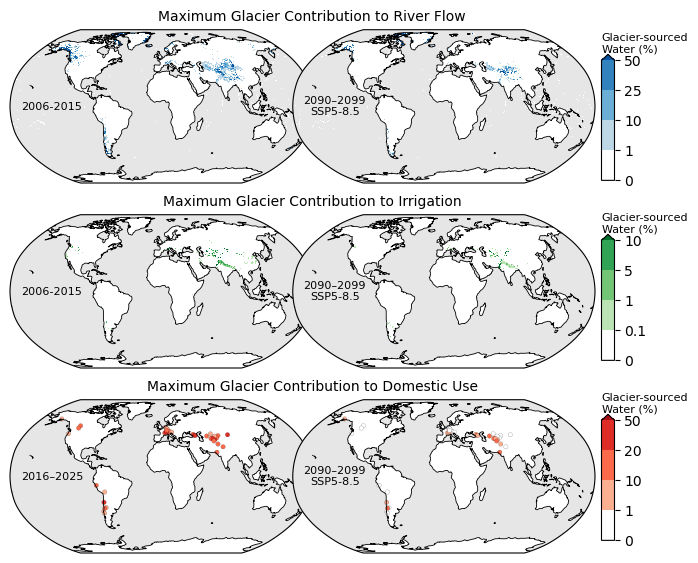

In [7]:
fig = plt.figure(figsize=(6.5, 6))

# Layout parameters
rows = 3
cols = 2

# Manual positioning (in figure fraction coordinates)
left_margin = 0.06
right_margin = 0.04
top_margin = 0.04
bottom_margin = 0.05

vertical_space = 0.015
horizontal_overlap = 0.03  # controls overlap amount

usable_height = 1 - top_margin - bottom_margin
usable_width = 1 - left_margin - right_margin

map_height = (usable_height - vertical_space * (rows - 1)) / rows
map_width = usable_width / 2 + horizontal_overlap / 2

axes = []

for r in range(rows):
    bottom = 1 - top_margin - (r + 1) * map_height - r * vertical_space
    
    # Left map
    ax_left = fig.add_axes(
        [left_margin, bottom, map_width, map_height],
        projection=ccrs.Robinson()
    )
    ax_left.set_zorder(1)
    axes.append(ax_left)
    
    # Right map (shifted left slightly to overlap)
    ax_right = fig.add_axes(
        [left_margin + map_width - horizontal_overlap,
         bottom,
         map_width,
         map_height],
        projection=ccrs.Robinson()
    )
    ax_right.set_zorder(2)  # ensure right overlaps left
    axes.append(ax_right)

# Add map features
for i, ax in enumerate(axes):
    ax.set_global()
    ax.coastlines(linewidth=0.6)
    ax.add_feature(cfeature.LAND, facecolor='white')
    ax.add_feature(cfeature.OCEAN, facecolor='0.9')

    # ----- MAXIMUM DISCHARGE OF ANY MONTH -----
    # Present-day
    if i == 0:
        # Discrete Colormap for Discharge Max
        bounds = [0, 1, 10, 25, 50]
        colors_all = ['white', '#bdd7e7', '#6baed6', '#3182bd', '#08519c'] # BLUES
        colors = colors_all[0:4]
        cmap = mcolors.ListedColormap(colors)
        cmap.set_over(colors_all[4])
        norm = mcolors.BoundaryNorm(bounds, cmap.N)

        # Map plot
        im = ax.pcolormesh(ds_qmax.longitude, ds_qmax.latitude,
                           100 * qmax_2006_2015,
                           transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
        # Time Label
        ax.text(-130, 0, '2006-2015', transform=ccrs.PlateCarree(), fontsize=8, ha='center', va='center')

        # Row Label
        bbox = ax.get_position()
        fig.text(bbox.x1, bbox.y1 + 0.01, 'Maximum Glacier Contribution to River Flow', ha='center', va='bottom', fontsize=10)

    # End-of-Century
    if i == 1:
        # Map plot
        im = ax.pcolormesh(ds_qmax.longitude, ds_qmax.latitude,
                           100 * qmax_multigcm_med_2090_2099,
                           transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
        # Time Label
        ax.text(-130, 0, '2090–2099\n' + ssp_name_dict[ssp], transform=ccrs.PlateCarree(), fontsize=8, ha='center', va='center')

        # Colorbar & label
        cax = fig.add_axes([0.97, 0.69, 0.02, 0.21])
        cbar = plt.colorbar(im, cax=cax, orientation='vertical', extend='max')
        tick_locs = bounds
        bin_labels = [str(int(x)) for x in bounds]
        cbar.set_ticks(tick_locs)
        cbar.set_ticklabels(bin_labels)
        # cbar.set_label('Glacier-sourced Water\n(%)', rotation=90, labelpad=10)
        cbar.ax.set_title('Glacier-sourced\nWater (%)', loc='left', pad=6, size=8)


    # ----- MAXIMUM CONTRIBUTION TO IRRIGATION OF ANY MONTH -----
    # Present-day
    if i == 2:
        # Discrete Colormap for Discharge Max
        bounds = [0, 0.1, 1, 5, 10]
        colors_all = ['white', '#bae4b3', '#74c476', '#31a354', '#006d2c'] # GREENS
        colors = colors_all[0:4]
        cmap = mcolors.ListedColormap(colors)
        cmap.set_over(colors_all[4])
        norm = mcolors.BoundaryNorm(bounds, cmap.N)

        # Map plot
        im = ax.pcolormesh(ds_irrmax.longitude, ds_irrmax.latitude,
                           100 * irrmax_2006_2015,
                           transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
        # Time Label
        ax.text(-130, 0, '2006-2015', transform=ccrs.PlateCarree(), fontsize=8, ha='center', va='center')

        # Row Label
        bbox = ax.get_position()
        fig.text(bbox.x1, bbox.y1 + 0.01, 'Maximum Glacier Contribution to Irrigation', ha='center', va='bottom', fontsize=10)

    # End-of-Century
    if i == 3:
        # Map plot
        im = ax.pcolormesh(ds_irrmax.longitude, ds_irrmax.latitude,
                           100 * irrmax_multigcm_med_2090_2099,
                           transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
        # Time Label
        ax.text(-130, 0, '2090–2099\n' + ssp_name_dict[ssp], transform=ccrs.PlateCarree(), fontsize=8, ha='center', va='center')

        # Colorbar & label
        cax = fig.add_axes([0.97, 0.39, 0.02, 0.21])
        cbar = plt.colorbar(im, cax=cax, orientation='vertical', extend='max')
        tick_locs = bounds
        bin_labels = [str(x) for x in bounds]
        cbar.set_ticks(tick_locs)
        cbar.set_ticklabels(bin_labels)
        # cbar.set_label('Glacier-sourced Water\n(%)', rotation=90, labelpad=10)
        cbar.ax.set_title('Glacier-sourced\nWater (%)', loc='left', pad=6, size=8)


    # ----- MAXIMUM CITY USE OF ANY MONTH -----
    # Present-day
    if i == 4:
        # Discrete Colormap for Discharge Max
        bounds = [0, 1, 10, 20, 50]
        colors_all = ['white', '#fcae91', '#fb6a4a', '#de2d26', '#a50f15'] # GREENS
        colors = colors_all[0:4]
        cmap = mcolors.ListedColormap(colors)
        cmap.set_over(colors_all[4])
        norm = mcolors.BoundaryNorm(bounds, cmap.N)

        # Map plot
        x, y = cities_gdf.geometry.x, cities_gdf.geometry.y
        im = ax.scatter(x, y, c=cities_gdf['2006_2015_mean']*100, 
                        s=10, edgecolor='black', lw=0.1,
                        transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
        # Time Label
        ax.text(-130, 0, '2016–2025', transform=ccrs.PlateCarree(), fontsize=8, ha='center', va='center')

        # Row Label
        bbox = ax.get_position()
        fig.text(bbox.x1, bbox.y1 + 0.01, 'Maximum Glacier Contribution to Domestic Use', ha='center', va='bottom', fontsize=10)

    # End-of-Century
    if i == 5:
        # Map plot
        x, y = cities_gdf.geometry.x, cities_gdf.geometry.y
        # ax.scatter(x, y, s=10, edgecolor='black', lw=0.1,
        #            transform=ccrs.PlateCarree(), color=cmap(norm(cities_gdf['2090_2099_mean']*100)))
        sc = ax.scatter(x, y, c=cities_gdf['2090_2099_mean']*100, 
                        s=10, edgecolor='black', lw=0.1,
                        transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
        # Time Label
        ax.text(-130, 0, '2090–2099\n' + ssp_name_dict[ssp], transform=ccrs.PlateCarree(), fontsize=8, ha='center', va='center')

        # Colorbar & label
        cax = fig.add_axes([0.97, 0.09, 0.02, 0.21])
        cbar = plt.colorbar(sc, cax=cax, orientation='vertical', extend='max')
        tick_locs = bounds
        bin_labels = [str(x) for x in bounds]
        cbar.set_ticks(tick_locs)
        cbar.set_ticklabels(bin_labels)
        # cbar.set_label('Glacier-sourced Water\n(%)', rotation=90, labelpad=10)
        cbar.ax.set_title('Glacier-sourced\nWater (%)', loc='left', pad=6, size=8)

fig.savefig(paper_fig_fp + 'map-global-change_flow_irr_dom-' + ssp + '.png', bbox_inches='tight', dpi=300)

plt.show()

<br><br><br><br>
# Subregional plots

In [8]:
def thicken_cartopy_edges_fulltop(ax, edges=("top",), linewidth=4, color="black"):
    """
    Thicken selected edges of a Cartopy GeoAxes curved projection boundary,
    with full top arc included for Robinson/Mollweide projections.

    Parameters
    ----------
    ax : GeoAxes
        The Cartopy axes to modify.
    edges : tuple
        Which edges to thicken: 'top', 'bottom', 'left', 'right'.
    linewidth : float
        Thickness of the selected edges.
    color : str
        Color of the thick border.
    """
    # Force rendering so boundary exists
    ax.figure.canvas.draw()
    
    # Make full boundary thin first
    ax.patch.set_linewidth(0.8)
    ax.patch.set_edgecolor(color)
    
    # Extract boundary path and transform
    boundary_path = ax.patch.get_path()
    boundary_transform = ax.patch.get_transform()
    
    # Vertices in projection/display coordinates
    verts = boundary_transform.transform(boundary_path.vertices)
    
    # Approximate map center
    x0, y0 = np.mean(verts[:, 0]), np.mean(verts[:, 1])
    
    for edge in edges:
        if edge.lower() == "top":
            # Keep all vertices with y above center (entire top arc)
            mask = verts[:, 1] > y0
        elif edge.lower() == "bottom":
            mask = verts[:, 1] < y0
        elif edge.lower() == "left":
            mask = verts[:, 0] < x0
        elif edge.lower() == "right":
            mask = verts[:, 0] > x0
        else:
            raise ValueError(f"Invalid edge '{edge}'. Choose from 'top', 'bottom', 'left', 'right'.")
        
        # Keep the longest contiguous segment
        indices = np.where(mask)[0]
        splits = np.split(indices, np.where(np.diff(indices) != 1)[0] + 1)
        longest_segment = max(splits, key=len)
        segment = verts[longest_segment]
        
        # Transform back to projection coordinates
        segment_proj = boundary_transform.inverted().transform(segment)
        
        # Draw as PathPatch
        path = mpath.Path(segment_proj)
        patch = mpatches.PathPatch(
            path,
            transform=ax.patch.get_transform(),
            facecolor='none',
            edgecolor=color,
            linewidth=linewidth,
            zorder=10
        )
        ax.add_patch(patch)


def thicken_cartopy_edges(ax, edges=("top", "bottom"), linewidth=4, tol=1.0, color="black"):
    """
    Thicken selected edges of a Cartopy GeoAxes curved projection boundary.
    
    Parameters
    ----------
    ax : GeoAxes
        The Cartopy axes to modify.
    edges : tuple
        Which edges to thicken: any combination of 'top', 'bottom', 'left', 'right'.
    linewidth : float
        Thickness of the selected edges.
    tol : float
        Tolerance in pixels to select vertices near edge.
    color : str
        Color of the thick border.
    """
    # Force rendering so boundary exists
    ax.figure.canvas.draw()
    
    # Make full boundary thin first
    ax.patch.set_linewidth(0.8)
    ax.patch.set_edgecolor(color)
    
    # Extract boundary path and transform
    boundary_path = ax.patch.get_path()
    boundary_transform = ax.patch.get_transform()
    
    # Convert vertices to display coordinates
    vertices = boundary_transform.transform(boundary_path.vertices)
    
    for edge in edges:
        if edge.lower() == "top":
            ymax = vertices[:, 1].max()
            seg = vertices[np.abs(vertices[:, 1] - ymax) < tol]
        elif edge.lower() == "bottom":
            ymin = vertices[:, 1].min()
            seg = vertices[np.abs(vertices[:, 1] - ymin) < tol]
        elif edge.lower() == "left":
            xmin = vertices[:, 0].min()
            seg = vertices[np.abs(vertices[:, 0] - xmin) < tol]
        elif edge.lower() == "right":
            xmax = vertices[:, 0].max()
            seg = vertices[np.abs(vertices[:, 0] - xmax) < tol]
        else:
            raise ValueError(f"Invalid edge '{edge}'. Choose from 'top', 'bottom', 'left', 'right'.")
        
        # Transform back to projection coordinates
        seg_proj = boundary_transform.inverted().transform(seg)
        
        # Create and add PathPatch
        path = mpath.Path(seg_proj)
        patch = mpatches.PathPatch(
            path,
            transform=ax.patch.get_transform(),
            facecolor='none',
            edgecolor=color,
            linewidth=linewidth,
            zorder=10
        )
        ax.add_patch(patch)

In [9]:
def add_subplot(region_bounds, subplot_loc, lon, lat, data, cmap, norm,
                projection_map=ccrs.Robinson(),
                add_cities=False, city_cn='2016_2025_mean',
                edges2bold=("top","left","right","bottom"),
                edgewidth=2.5, extraedge=False):
    """
    Add a subplot of a given subregion and variable to the main figure, with optional thickened edges and label.

    Parameters
    ----------
    region_bounds : list
        [lon_min, lon_max, lat_min, lat_max] for the map extent.
    subplot_loc : list
        [left, bottom, width, height] for subplot placement.
    lon, lat : arrays
        Coordinates of the data grid.
    data : array
        Data to plot.
    cmap : matplotlib colormap
        Colormap for the plot.
    norm : matplotlib norm
        Normalization for colormap.
    projection_map : cartopy.crs
        Map projection.
    add_cities : bool
        Whether to plot cities from `cities_gdf`.
    city_cn : str
        Column name for city values.
    edges2bold : tuple
        Which edges to thicken: any combination of 'top', 'bottom', 'left', 'right'.
    edgewidth : float
        Width of thickened edges.
    label_text : str or None
        Optional text label over the subplot.
    label_props : dict or None
        Properties for the label text box.
    
    Returns
    -------
    ax_sub : GeoAxes
        The Cartopy axes for the subplot.
    im : QuadMesh
        The pcolormesh object.
    """

    # Set up subplot
    ax_sub = fig.add_axes(subplot_loc, projection=projection_map)

    # Plot variable
    im = ax_sub.pcolormesh(lon, lat, data, transform=ccrs.PlateCarree(),
                           cmap=cmap, norm=norm, zorder=0)

    # Set extent
    ax_sub.set_extent(region_bounds, crs=ccrs.PlateCarree())

    # Add coastlines and ocean
    ax_sub.coastlines(linewidth=0.6, zorder=3)
    ax_sub.add_feature(cfeature.OCEAN, facecolor='lightgrey')

    # Add cities
    if add_cities:
        cities_sorted = cities_gdf.sort_values(by='POP', ascending=False)
        
        x, y = cities_sorted.geometry.x, cities_sorted.geometry.y
        sizes = cities_sorted['POP'].apply(
            lambda pop: 8 if pop < 250000 else
                        16 if pop <= 500000 else
                        32  # Adjust size values as necessary
            )
        ax_sub.scatter(x, y, c=cities_sorted[city_cn]*100,
                       s=sizes, edgecolor='black', lw=0.4,
                       transform=ccrs.PlateCarree(), cmap=cmap, norm=norm, zorder=4)

    # reg_gdf.plot(ax=ax_sub, edgecolor='blue', facecolor='none')

    # Thicken only selected edges
    thicken_cartopy_edges(ax_sub, edges=edges2bold, linewidth=edgewidth)
    if extraedge:
        thicken_cartopy_edges_fulltop(ax_sub, edges=edges2bold, linewidth=edgewidth)

    return ax_sub, im

## Discharge: present and future

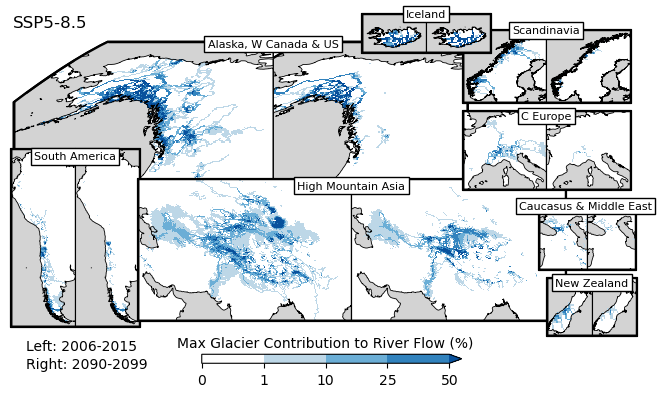

In [10]:
data1 = 100 * qmax_2006_2015
data2 = 100 * qmax_multigcm_med_2090_2099
lon = ds_qmax.longitude
lat = ds_qmax.latitude

# Define colormap and norm
bounds = [0, 1, 10, 25, 50]
colors_all = ['white', '#bdd7e7', '#6baed6', '#3182bd', '#08519c']  # BLUES
colors = colors_all[0:4]
cmap1 = mcolors.ListedColormap(colors)
cmap1.set_over(colors_all[4])
norm1 = mcolors.BoundaryNorm(bounds, cmap1.N)

# make clear
data1[data1 <= bounds[1]] = np.nan
data2[data2 <= bounds[1]] = np.nan

# Use same colorbars for both plots
cmap2 = cmap1
norm2 = norm1

# Textbox properties
edgewidth=2.5
props = dict(boxstyle='square', facecolor='white', edgecolor='black', linewidth=1)
    

# ------ CREATE FIGURE ----- 
fig = plt.figure(figsize=(6.5, 6))

# ----- NORTH AMERICA -----
region_bounds = [-158,-120, 42, 75]
subplot_loc1 = [0.01, 0.5, 0.4, 0.4]
subplot_loc2 = [0.31, 0.5, 0.4, 0.4]
# Future
# ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2)
ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth, extraedge=True)
# Present
ax_NA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth, extraedge=True)
# Label
ax_NA1.text(1, 0.98, "Alaska, W Canada & US",
            transform=ax_NA1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)

# ----- SOUTH AMERICA -----
region_bounds = [-82, -65, -57, 13]
subplot_loc1 = [0.005, -0.01, 0.1, 1]
subplot_loc2 = [0.105, -0.01, 0.1, 1]
# Present
ax_SA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_SA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_SA2.text(1, 0.98, "South America",
            transform=ax_SA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# # ----- High Mountain Asia -----
region_bounds = [53, 108, 18, 55]
subplot_loc1 = [0.2, 0.295, 0.33, 0.35]
subplot_loc2 = [0.53, 0.295, 0.33, 0.35]
# Present
ax_HMA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                           edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_HMA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                           edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_HMA2.text(1, 0.98, "High Mountain Asia",
            transform=ax_HMA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- SCANDINAVIA -----
region_bounds = [4,23.5,57.5,72]
subplot_loc1 = [0.70, 0.70, 0.13, 0.15]
subplot_loc2 = [0.83, 0.70, 0.13, 0.15]
# Present
ax_S1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_S2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_S2.text(1, 0.98, "Scandinavia",
           transform=ax_S1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- Iceland -----
region_bounds = [-25,-13,62.5,68.7]
subplot_loc1 = [0.545, 0.78, 0.1, 0.1]
subplot_loc2 = [0.645, 0.78, 0.1, 0.1]
# Present
ax_I1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_I2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_I2.text(1, 0.98, "Iceland",
           transform=ax_I1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- CENTRAL EUROPE -----
region_bounds = [-2,19,38.2,55]
subplot_loc1 = [0.70, 0.561, 0.13, 0.15]
subplot_loc2 = [0.83, 0.561, 0.13, 0.15]
# Present
ax_CE1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_CE2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_CE2.text(1, 0.98, "C Europe",
            transform=ax_CE1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- CAUCASUS & Middle East -----
region_bounds = [36,51,30,49]
subplot_loc1 = [0.805, 0.435, 0.1, 0.1]
subplot_loc2 = [0.88, 0.435, 0.1, 0.1]
# Present
ax_C1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_C2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_C2.text(0.97, 0.99, "Caucasus & Middle East",
           transform=ax_C1.transAxes, fontsize=8, ha='center', va='bottom', bbox=props, zorder=20)


# ----- New Zealand -----
region_bounds = [167,175,-47,-39]
subplot_loc1 = [0.83, 0.325, 0.07, 0.1]
subplot_loc2 = [0.9, 0.325, 0.07, 0.1]
# change projection so New Zealand looks normal
projection_NZ = ccrs.TransverseMercator(central_longitude=173.0, central_latitude=0.0,
                                        false_easting=1600000, false_northing=10000000,
                                        scale_factor=0.9996, globe=ccrs.Globe(datum='WGS84', ellipse='GRS80'))
# Present
ax_NZ1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, projection_map=projection_NZ,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_NZ2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2, projection_map=projection_NZ,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_NZ2.text(1, 0.98, "New Zealand",
            transform=ax_NZ1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- ADD COLORBAR -----
cbar_ax = fig.add_axes([0.3, 0.28, 0.4, 0.015])
cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal', extend='max')
cbar.set_label('Max Glacier Contribution to River Flow (%)', fontsize=10, labelpad=-37)

# ----- SSP Label -----
fig.text(0.01, 0.86, ssp_name_dict[ssp], fontsize=12, ha='left', va='top')
fig.text(0.03, 0.32, 'Left: 2006-2015', fontsize=10, ha='left', va='top')
fig.text(0.03, 0.29, 'Right: 2090-2099', fontsize=10, ha='left', va='top')


# Adjust layout to prevent overlap
fig.savefig(paper_fig_fp + 'maps-subregions-qmax-' + ssp + '.png', bbox_inches='tight', dpi=300)
plt.show()

## Discharge: Future (two SSPs)
Add SSP5-8.5 to plot with SSP2-4.5

In [11]:
# Process SSP5-8.5 for a difference plot
if ssp == 'ssp245':

    plot_2futures = True
    
    qmax_gcms = None
    for ngcm, gcm_name in enumerate(gcm_names):
    
        qmax_fn = gcm_name + '_ssp585_max_discharge_m3s_pg_frac.nc'
    
        ds_qmax = xr.open_dataset(qmax_fp + qmax_fn)
    
        qmax = ds_qmax['max_monthly_frac'].values
    
        if qmax_gcms is None:
            qmax_gcms = qmax[np.newaxis,:,:,:]
        else:
            qmax_gcms = np.concatenate((qmax_gcms, qmax[np.newaxis,:,:,:]), axis=0)
    
    # 2090-2100
    qmax_gcms_2090_2099_mean_ssp585 = np.nanmean(qmax_gcms[:,-10:,:,:], axis=1)
    qmax_multigcm_med_2090_2099_ssp585 = np.nanmedian(qmax_gcms_2090_2099_mean_ssp585, axis=0)

else:
    plot_2futures = False

In [12]:
if plot_2futures:

    data1 = 100 * qmax_multigcm_med_2090_2099
    data2 = 100 * qmax_multigcm_med_2090_2099_ssp585
    lon = ds_qmax.longitude
    lat = ds_qmax.latitude
    
    # Define colormap and norm
    bounds = [0, 1, 10, 25, 50]
    colors_all = ['white', '#bdd7e7', '#6baed6', '#3182bd', '#08519c']  # BLUES
    colors = colors_all[0:4]
    cmap1 = mcolors.ListedColormap(colors)
    cmap1.set_over(colors_all[4])
    norm1 = mcolors.BoundaryNorm(bounds, cmap1.N)
    
    # make clear
    data1[data1 <= bounds[1]] = np.nan
    data2[data2 <= bounds[1]] = np.nan
    
    # Use same colorbars for both plots
    cmap2 = cmap1
    norm2 = norm1
    
    # Textbox properties
    edgewidth=2.5
    props = dict(boxstyle='square', facecolor='white', edgecolor='black', linewidth=1)
        
    
    # ------ CREATE FIGURE ----- 
    fig = plt.figure(figsize=(6.5, 6))
    
    # ----- NORTH AMERICA -----
    region_bounds = [-158,-120, 42, 75]
    subplot_loc1 = [0.01, 0.5, 0.4, 0.4]
    subplot_loc2 = [0.31, 0.5, 0.4, 0.4]
    # Future
    # ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2)
    ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                              edges2bold=("top","bottom","right"), edgewidth=edgewidth, extraedge=True)
    # Present
    ax_NA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                              edges2bold=("top","bottom","left"), edgewidth=edgewidth, extraedge=True)
    # Label
    ax_NA1.text(1, 0.98, "Alaska, W Canada & US",
                transform=ax_NA1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)
    
    # ----- SOUTH AMERICA -----
    region_bounds = [-82, -65, -57, 13]
    subplot_loc1 = [0.005, -0.01, 0.1, 1]
    subplot_loc2 = [0.105, -0.01, 0.1, 1]
    # Present
    ax_SA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                              edges2bold=("top","bottom","left"), edgewidth=edgewidth)
    # Future
    ax_SA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                              edges2bold=("top","bottom","right"), edgewidth=edgewidth)
    # Label
    ax_SA2.text(1, 0.98, "South America",
                transform=ax_SA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)
    
    
    # # ----- High Mountain Asia -----
    region_bounds = [53, 108, 18, 55]
    subplot_loc1 = [0.2, 0.295, 0.33, 0.35]
    subplot_loc2 = [0.53, 0.295, 0.33, 0.35]
    # Present
    ax_HMA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                               edges2bold=("top","bottom","left"), edgewidth=edgewidth)
    # Future
    ax_HMA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                               edges2bold=("top","bottom","right"), edgewidth=edgewidth)
    # Label
    ax_HMA2.text(1, 0.98, "High Mountain Asia",
                transform=ax_HMA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)
    
    
    # ----- SCANDINAVIA -----
    region_bounds = [4,23.5,57.5,72]
    subplot_loc1 = [0.70, 0.70, 0.13, 0.15]
    subplot_loc2 = [0.83, 0.70, 0.13, 0.15]
    # Present
    ax_S1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                             edges2bold=("top","bottom","left"), edgewidth=edgewidth)
    # Future
    ax_S2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                             edges2bold=("top","bottom","right"), edgewidth=edgewidth)
    # Label
    ax_S2.text(1, 0.98, "Scandinavia",
               transform=ax_S1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)
    
    
    # ----- Iceland -----
    region_bounds = [-25,-13,62.5,68.7]
    subplot_loc1 = [0.545, 0.78, 0.1, 0.1]
    subplot_loc2 = [0.645, 0.78, 0.1, 0.1]
    # Present
    ax_I1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                             edges2bold=("top","bottom","left"), edgewidth=edgewidth)
    # Future
    ax_I2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                             edges2bold=("top","bottom","right"), edgewidth=edgewidth)
    # Label
    ax_I2.text(1, 0.98, "Iceland",
               transform=ax_I1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)
    
    
    # ----- CENTRAL EUROPE -----
    region_bounds = [-2,19,38.2,55]
    subplot_loc1 = [0.70, 0.561, 0.13, 0.15]
    subplot_loc2 = [0.83, 0.561, 0.13, 0.15]
    # Present
    ax_CE1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                              edges2bold=("top","bottom","left"), edgewidth=edgewidth)
    # Future
    ax_CE2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                              edges2bold=("top","bottom","right"), edgewidth=edgewidth)
    # Label
    ax_CE2.text(1, 0.98, "C Europe",
                transform=ax_CE1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)
    
    
    # ----- CAUCASUS & Middle East -----
    region_bounds = [36,51,30,49]
    subplot_loc1 = [0.805, 0.435, 0.1, 0.1]
    subplot_loc2 = [0.88, 0.435, 0.1, 0.1]
    # Present
    ax_C1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                             edges2bold=("top","bottom","left"), edgewidth=edgewidth)
    # Future
    ax_C2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                             edges2bold=("top","bottom","right"), edgewidth=edgewidth)
    # Label
    ax_C2.text(0.97, 0.99, "Caucasus & Middle East",
               transform=ax_C1.transAxes, fontsize=8, ha='center', va='bottom', bbox=props, zorder=20)
    
    
    # ----- New Zealand -----
    region_bounds = [167,175,-47,-39]
    subplot_loc1 = [0.83, 0.325, 0.07, 0.1]
    subplot_loc2 = [0.9, 0.325, 0.07, 0.1]
    # change projection so New Zealand looks normal
    projection_NZ = ccrs.TransverseMercator(central_longitude=173.0, central_latitude=0.0,
                                            false_easting=1600000, false_northing=10000000,
                                            scale_factor=0.9996, globe=ccrs.Globe(datum='WGS84', ellipse='GRS80'))
    # Present
    ax_NZ1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, projection_map=projection_NZ,
                              edges2bold=("top","bottom","left"), edgewidth=edgewidth)
    # Future
    ax_NZ2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2, projection_map=projection_NZ,
                              edges2bold=("top","bottom","right"), edgewidth=edgewidth)
    # Label
    ax_NZ2.text(1, 0.98, "New Zealand",
                transform=ax_NZ1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)
    
    
    # ----- ADD COLORBAR -----
    cbar_ax = fig.add_axes([0.3, 0.28, 0.4, 0.015])
    cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal', extend='max')
    cbar.set_label('Max Glacier Contribution to River Flow (%)', fontsize=10, labelpad=-37)
    
    # ----- SSP Label -----
    fig.text(0.01, 0.86, '2090-2099', fontsize=12, ha='left', va='top')
    fig.text(0.03, 0.32, 'Left: SSP2-4.5', fontsize=10, ha='left', va='top')
    fig.text(0.03, 0.29, 'Right: SSP5-8.5', fontsize=10, ha='left', va='top')
    
    
    # Adjust layout to prevent overlap
    fig.savefig(paper_fig_fp + 'maps-subregions-qmax-2090s-' + ssp + '-ssp585.png', bbox_inches='tight', dpi=300)
    plt.show()

## Discharge: Present-day and Difference

In [13]:
# Set nan values to 0 for the difference; otherwise, they don't show up even if there were values in earlier timesteps
qmax_multigcm_med_2090_2099_nanfilled = qmax_multigcm_med_2090_2099.copy()
mask = np.isnan(qmax_multigcm_med_2090_2099) & (qmax_2006_2015 > 0)
qmax_multigcm_med_2090_2099_nanfilled[mask] = 0

qmax_multigcm_med_dif = qmax_multigcm_med_2090_2099_nanfilled - qmax_2006_2015
qmax_multigcm_med_dif_masked = np.ma.masked_where(np.abs(qmax_multigcm_med_dif) < 0.01, qmax_multigcm_med_dif)

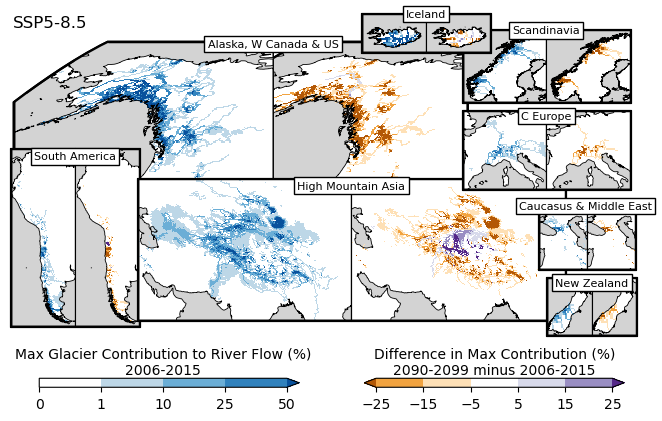

In [14]:
data1 = 100 * qmax_2006_2015
data2 = 100 * qmax_multigcm_med_dif_masked
lon = ds_qmax.longitude
lat = ds_qmax.latitude

# Define colormap and norm
bounds = [0, 1, 10, 25, 50]
colors_all = ['white', '#bdd7e7', '#6baed6', '#3182bd', '#08519c']  # BLUES
colors = colors_all[0:4]
cmap1 = mcolors.ListedColormap(colors)
cmap1.set_over(colors_all[4])
norm1 = mcolors.BoundaryNorm(bounds, cmap1.N)

# Difference colormap
# # cmap_dif = plt.get_cmap('RdYlBu')
# # norm_dif = Normalize(vmin=-20, vmax=20)
bounds_2 = [-25, -15, -5, 5, 15, 25]
colors_all_2 = ['#b35806', '#f1a340', '#fee0b6', 'white', '#d8daeb', '#998ec3', '#542788']
colors_2 = colors_all_2[1:6]
cmap2 = mcolors.ListedColormap(colors_2)
cmap2.set_over(colors_all_2[6])
cmap2.set_under(colors_all_2[0])
norm2 = mcolors.BoundaryNorm(bounds_2, cmap2.N)

# Filter data (plots underlying lakes, etc.)
data1[data1 <= bounds[1]] = np.nan
data2[(data2 >= bounds_2[2]) & (data2 <= bounds_2[3])] = np.nan

# Textbox properties
edgewidth=2.5
props = dict(boxstyle='square', facecolor='white', edgecolor='black', linewidth=1)
    

# ------ CREATE FIGURE ----- 
fig = plt.figure(figsize=(6.5, 6))

# ----- NORTH AMERICA -----
region_bounds = [-158,-120, 42, 75]
subplot_loc1 = [0.01, 0.5, 0.4, 0.4]
subplot_loc2 = [0.31, 0.5, 0.4, 0.4]
# Future
# ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2)
ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth, extraedge=True)
# Present
ax_NA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth, extraedge=True)
# Label
ax_NA1.text(1, 0.98, "Alaska, W Canada & US",
            transform=ax_NA1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)

# ----- SOUTH AMERICA -----
region_bounds = [-82, -65, -57, 13]
subplot_loc1 = [0.005, -0.01, 0.1, 1]
subplot_loc2 = [0.105, -0.01, 0.1, 1]
# Present
ax_SA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_SA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_SA2.text(1, 0.98, "South America",
            transform=ax_SA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# # ----- High Mountain Asia -----
region_bounds = [53, 108, 18, 55]
subplot_loc1 = [0.2, 0.295, 0.33, 0.35]
subplot_loc2 = [0.53, 0.295, 0.33, 0.35]
# Present
ax_HMA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                           edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_HMA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                           edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_HMA2.text(1, 0.98, "High Mountain Asia",
            transform=ax_HMA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- SCANDINAVIA -----
region_bounds = [4,23.5,57.5,72]
subplot_loc1 = [0.70, 0.70, 0.13, 0.15]
subplot_loc2 = [0.83, 0.70, 0.13, 0.15]
# Present
ax_S1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_S2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_S2.text(1, 0.98, "Scandinavia",
           transform=ax_S1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- Iceland -----
region_bounds = [-25,-13,62.5,68.7]
subplot_loc1 = [0.545, 0.78, 0.1, 0.1]
subplot_loc2 = [0.645, 0.78, 0.1, 0.1]
# Present
ax_I1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_I2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_I2.text(1, 0.98, "Iceland",
           transform=ax_I1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- CENTRAL EUROPE -----
region_bounds = [-2,19,38.2,55]
subplot_loc1 = [0.70, 0.561, 0.13, 0.15]
subplot_loc2 = [0.83, 0.561, 0.13, 0.15]
# Present
ax_CE1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_CE2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_CE2.text(1, 0.98, "C Europe",
            transform=ax_CE1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- CAUCASUS & Middle East -----
region_bounds = [36,51,30,49]
subplot_loc1 = [0.805, 0.435, 0.1, 0.1]
subplot_loc2 = [0.88, 0.435, 0.1, 0.1]
# Present
ax_C1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_C2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_C2.text(0.97, 0.99, "Caucasus & Middle East",
           transform=ax_C1.transAxes, fontsize=8, ha='center', va='bottom', bbox=props, zorder=20)


# ----- New Zealand -----
region_bounds = [167,175,-47,-39]
subplot_loc1 = [0.83, 0.325, 0.07, 0.1]
subplot_loc2 = [0.9, 0.325, 0.07, 0.1]
# change projection so New Zealand looks normal
projection_NZ = ccrs.TransverseMercator(central_longitude=173.0, central_latitude=0.0,
                                        false_easting=1600000, false_northing=10000000,
                                        scale_factor=0.9996, globe=ccrs.Globe(datum='WGS84', ellipse='GRS80'))
# Present
ax_NZ1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, projection_map=projection_NZ,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_NZ2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2, projection_map=projection_NZ,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_NZ2.text(1, 0.98, "New Zealand",
            transform=ax_NZ1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)

# ----- ADD COLORBAR -----
cbar_ax = fig.add_axes([0.05, 0.24, 0.4, 0.015])
cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal', extend='max')
cbar.set_label('Max Glacier Contribution to River Flow (%)\n2006-2015', fontsize=10, labelpad=-46)

cbar_ax2 = fig.add_axes([0.55, 0.24, 0.4, 0.015])
cbar2 = fig.colorbar(im2, cax=cbar_ax2, orientation='horizontal', extend='both')
cbar2.set_label('Difference in Max Contribution (%)\n2090-2099 minus 2006-2015', fontsize=10, labelpad=-46)

# ----- SSP Label -----
fig.text(0.01, 0.86, ssp_name_dict[ssp], fontsize=12, ha='left', va='top')


# Adjust layout to prevent overlap
fig.savefig(paper_fig_fp + 'maps-subregions-qmax_dif-' + ssp + '.png', bbox_inches='tight', dpi=300)
plt.show()

### With cities

In [15]:
cities_gdf['2090_2099-minus-2006_2015'] = cities_gdf['2090_2099_mean'] - cities_gdf['2006_2015_mean']
cities_gdf.head()

,name,geometry,city_name,FID,CITY_NAME,CNTRY_NAME,1980,1981,1982,1983,...,2095,2096,2097,2098,2099,max_2006_2099,2006_2015_mean,2090_2099_mean,POP,2090_2099-minus-2006_2015
0,"La Paz, Bolivia",POINT (-68.11930 -16.48970),La Paz,15,La Paz,Bolivia,0.058631,0.072267,0.049452,0.068177,...,0.000996,0.001161,0.000856,0.000828,0.000690,0.121831,0.088927,0.001137,2143000,-0.087790
1,"Concepcion, Chile",POINT (-73.04980 -36.82700),Concepcion,32,Concepcion,Chile,0.029971,0.039419,0.058585,0.036605,...,0.001074,0.001546,0.001063,0.001011,0.000587,0.119641,0.073250,0.001871,238092,-0.071379
2,"Temuco, Chile",POINT (-72.59040 -38.73590),Temuco,33,Temuco,Chile,0.000000,0.000000,0.000000,0.000000,...,0.002983,0.005828,0.002641,0.002478,0.002948,0.170102,0.033861,0.004073,302931,-0.029788
3,"Copiapo, Chile",POINT (-70.33220 -27.36680),Copiapo,37,Copiapo,Chile,0.009505,0.110523,0.323255,0.066283,...,0.020278,0.018862,0.034421,0.025569,0.022706,0.941238,0.499693,0.031336,171766,-0.468357
4,"Mendoza, Argentina",POINT (-68.84580 -32.88950),Mendoza,40,Mendoza,Argentina,0.001969,0.000992,0.026368,0.000142,...,0.005964,0.006778,0.006758,0.006074,0.005443,0.110436,0.055043,0.007223,1025407,-0.047820


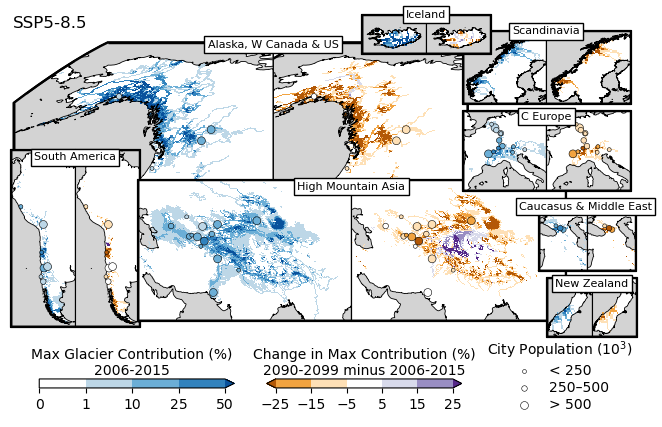

In [16]:
data1 = 100 * qmax_2006_2015
data2 = 100 * qmax_multigcm_med_dif_masked
lon = ds_qmax.longitude
lat = ds_qmax.latitude

# Define colormap and norm
bounds = [0, 1, 10, 25, 50]
colors_all = ['white', '#bdd7e7', '#6baed6', '#3182bd', '#08519c']  # BLUES
colors = colors_all[0:4]
cmap1 = mcolors.ListedColormap(colors)
cmap1.set_over(colors_all[4])
norm1 = mcolors.BoundaryNorm(bounds, cmap1.N)

# Difference colormap
# # cmap_dif = plt.get_cmap('RdYlBu')
# # norm_dif = Normalize(vmin=-20, vmax=20)
bounds_2 = [-25, -15, -5, 5, 15, 25]
colors_all_2 = ['#b35806', '#f1a340', '#fee0b6', 'white', '#d8daeb', '#998ec3', '#542788']
colors_2 = colors_all_2[1:6]
cmap2 = mcolors.ListedColormap(colors_2)
cmap2.set_over(colors_all_2[6])
cmap2.set_under(colors_all_2[0])
norm2 = mcolors.BoundaryNorm(bounds_2, cmap2.N)

# Filter data (plots underlying lakes, etc.)
data1[data1 <= bounds[1]] = np.nan
data2[(data2 >= bounds_2[2]) & (data2 <= bounds_2[3])] = np.nan

# Textbox properties
edgewidth=2.5
props = dict(boxstyle='square', facecolor='white', edgecolor='black', linewidth=1)
    

# ------ CREATE FIGURE ----- 
fig = plt.figure(figsize=(6.5, 6))

# ----- NORTH AMERICA -----
region_bounds = [-158,-120, 42, 75]
subplot_loc1 = [0.01, 0.5, 0.4, 0.4]
subplot_loc2 = [0.31, 0.5, 0.4, 0.4]
# Future
# ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2)
ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          add_cities=True, city_cn='2090_2099-minus-2006_2015',
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth, extraedge=True)
# Present
ax_NA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          add_cities=True, city_cn='2006_2015_mean',
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth, extraedge=True)
# Label
ax_NA1.text(1, 0.98, "Alaska, W Canada & US",
            transform=ax_NA1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)

# ----- SOUTH AMERICA -----
region_bounds = [-82, -65, -57, 13]
subplot_loc1 = [0.005, -0.01, 0.1, 1]
subplot_loc2 = [0.105, -0.01, 0.1, 1]
# Present
ax_SA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          add_cities=True, city_cn='2006_2015_mean',
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_SA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          add_cities=True, city_cn='2090_2099-minus-2006_2015',
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_SA2.text(1, 0.98, "South America",
            transform=ax_SA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# # ----- High Mountain Asia -----
region_bounds = [53, 108, 18, 55]
subplot_loc1 = [0.2, 0.295, 0.33, 0.35]
subplot_loc2 = [0.53, 0.295, 0.33, 0.35]
# Present
ax_HMA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          add_cities=True, city_cn='2006_2015_mean',
                           edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_HMA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                           add_cities=True, city_cn='2090_2099-minus-2006_2015',
                           edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_HMA2.text(1, 0.98, "High Mountain Asia",
            transform=ax_HMA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- SCANDINAVIA -----
region_bounds = [4,23.5,57.5,72]
subplot_loc1 = [0.70, 0.70, 0.13, 0.15]
subplot_loc2 = [0.83, 0.70, 0.13, 0.15]
# Present
ax_S1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                         add_cities=True, city_cn='2006_2015_mean',
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_S2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         add_cities=True, city_cn='2090_2099-minus-2006_2015',
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_S2.text(1, 0.98, "Scandinavia",
           transform=ax_S1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- Iceland -----
region_bounds = [-25,-13,62.5,68.7]
subplot_loc1 = [0.545, 0.78, 0.1, 0.1]
subplot_loc2 = [0.645, 0.78, 0.1, 0.1]
# Present
ax_I1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                         add_cities=True, city_cn='2006_2015_mean',
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_I2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         add_cities=True, city_cn='2090_2099-minus-2006_2015',
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_I2.text(1, 0.98, "Iceland",
           transform=ax_I1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- CENTRAL EUROPE -----
region_bounds = [-2,19,38.2,55]
subplot_loc1 = [0.70, 0.561, 0.13, 0.15]
subplot_loc2 = [0.83, 0.561, 0.13, 0.15]
# Present
ax_CE1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          add_cities=True, city_cn='2006_2015_mean',
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_CE2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          add_cities=True, city_cn='2090_2099-minus-2006_2015',
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_CE2.text(1, 0.98, "C Europe",
            transform=ax_CE1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- CAUCASUS & Middle East -----
region_bounds = [36,51,30,49]
subplot_loc1 = [0.805, 0.435, 0.1, 0.1]
subplot_loc2 = [0.88, 0.435, 0.1, 0.1]
# Present
ax_C1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                         add_cities=True, city_cn='2006_2015_mean',
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_C2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         add_cities=True, city_cn='2090_2099-minus-2006_2015',
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_C2.text(0.97, 0.99, "Caucasus & Middle East",
           transform=ax_C1.transAxes, fontsize=8, ha='center', va='bottom', bbox=props, zorder=20)


# ----- New Zealand -----
region_bounds = [167,175,-47,-39]
subplot_loc1 = [0.83, 0.325, 0.07, 0.1]
subplot_loc2 = [0.9, 0.325, 0.07, 0.1]
# change projection so New Zealand looks normal
projection_NZ = ccrs.TransverseMercator(central_longitude=173.0, central_latitude=0.0,
                                        false_easting=1600000, false_northing=10000000,
                                        scale_factor=0.9996, globe=ccrs.Globe(datum='WGS84', ellipse='GRS80'))
# Present
ax_NZ1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, projection_map=projection_NZ, 
                          add_cities=True, city_cn='2006_2015_mean',
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_NZ2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2, projection_map=projection_NZ,
                          add_cities=True, city_cn='2090_2099-minus-2006_2015',
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_NZ2.text(1, 0.98, "New Zealand",
            transform=ax_NZ1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- ADD COLORBAR -----
cbar_ax = fig.add_axes([0.05, 0.24, 0.3, 0.015])
cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal', extend='max')
cbar.set_label('Max Glacier Contribution (%)\n2006-2015', fontsize=10, labelpad=-46)

cbar_ax2 = fig.add_axes([0.40, 0.24, 0.3, 0.015])
cbar2 = fig.colorbar(im2, cax=cbar_ax2, orientation='horizontal', extend='both')
cbar2.set_label('Change in Max Contribution (%)\n2090-2099 minus 2006-2015', fontsize=10, labelpad=-46)

# Create dummy scatter points for legend
legend_handles = [
    ax_HMA1.scatter([], [], s=8, edgecolor='black', facecolor='white', lw=0.4, label='< 250'),
    ax_HMA1.scatter([], [], s=16, edgecolor='black', facecolor='white', lw=0.4, label='250–500'),
    ax_HMA1.scatter([], [], s=32, edgecolor='black', facecolor='white', lw=0.4, label='> 500')
]

# Add legend to the entire figure
fig.legend(handles=legend_handles, title='City Population (10$^{3}$)', labelspacing=0.2, fontsize=10,
           loc='lower left', bbox_to_anchor=(0.72, 0.18), ncol=1, frameon=False)

# ----- SSP Label -----
fig.text(0.01, 0.86, ssp_name_dict[ssp], fontsize=12, ha='left', va='top')

# Adjust layout to prevent overlap
fig.savefig(paper_fig_fp + 'maps-subregions-qmax_dif-wcities-' + ssp + '.png', bbox_inches='tight', dpi=300)
plt.show()

## Irrigation: Present and Future

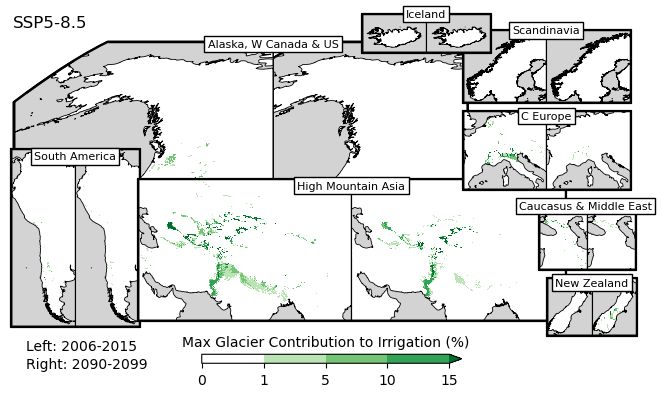

In [17]:
data1 = 100 * irrmax_2006_2015
data2 = 100 * irrmax_multigcm_med_2090_2099
lon = ds_qmax.longitude
lat = ds_qmax.latitude

# Define colormap and norm
bounds = [0, 1, 5, 10, 15]
colors_all = ['white', '#bae4b3', '#74c476', '#31a354', '#006d2c']  # GREENS

colors = colors_all[0:4]
cmap1 = mcolors.ListedColormap(colors)
cmap1.set_over(colors_all[4])
norm1 = mcolors.BoundaryNorm(bounds, cmap1.N)

# Use same colorbars for both plots
cmap2 = cmap1
norm2 = norm1

# Filter data (plots underlying lakes, etc.)
data1[data1 <= bounds[1]] = np.nan
data2[data2 <= bounds_2[1]] = np.nan


# Textbox properties
edgewidth=2.5
props = dict(boxstyle='square', facecolor='white', edgecolor='black', linewidth=1)
    

# ------ CREATE FIGURE ----- 
fig = plt.figure(figsize=(6.5, 6))

# ----- NORTH AMERICA -----
region_bounds = [-158,-120, 42, 75]
subplot_loc1 = [0.01, 0.5, 0.4, 0.4]
subplot_loc2 = [0.31, 0.5, 0.4, 0.4]
# Future
# ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2)
ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth, extraedge=True)
# Present
ax_NA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth, extraedge=True)
# Label
ax_NA1.text(1, 0.98, "Alaska, W Canada & US",
            transform=ax_NA1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)

# ----- SOUTH AMERICA -----
region_bounds = [-82, -65, -57, 13]
subplot_loc1 = [0.005, -0.01, 0.1, 1]
subplot_loc2 = [0.105, -0.01, 0.1, 1]
# Present
ax_SA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_SA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_SA2.text(1, 0.98, "South America",
            transform=ax_SA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# # ----- High Mountain Asia -----
region_bounds = [53, 108, 18, 55]
subplot_loc1 = [0.2, 0.295, 0.33, 0.35]
subplot_loc2 = [0.53, 0.295, 0.33, 0.35]
# Present
ax_HMA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                           edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_HMA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                           edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_HMA2.text(1, 0.98, "High Mountain Asia",
            transform=ax_HMA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- SCANDINAVIA -----
region_bounds = [4,23.5,57.5,72]
subplot_loc1 = [0.70, 0.70, 0.13, 0.15]
subplot_loc2 = [0.83, 0.70, 0.13, 0.15]
# Present
ax_S1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_S2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_S2.text(1, 0.98, "Scandinavia",
           transform=ax_S1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- Iceland -----
region_bounds = [-25,-13,62.5,68.7]
subplot_loc1 = [0.545, 0.78, 0.1, 0.1]
subplot_loc2 = [0.645, 0.78, 0.1, 0.1]
# Present
ax_I1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_I2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_I2.text(1, 0.98, "Iceland",
           transform=ax_I1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- CENTRAL EUROPE -----
region_bounds = [-2,19,38.2,55]
subplot_loc1 = [0.70, 0.561, 0.13, 0.15]
subplot_loc2 = [0.83, 0.561, 0.13, 0.15]
# Present
ax_CE1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_CE2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_CE2.text(1, 0.98, "C Europe",
            transform=ax_CE1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- CAUCASUS & Middle East -----
region_bounds = [36,51,30,49]
subplot_loc1 = [0.805, 0.435, 0.1, 0.1]
subplot_loc2 = [0.88, 0.435, 0.1, 0.1]
# Present
ax_C1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_C2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_C2.text(0.97, 0.99, "Caucasus & Middle East",
           transform=ax_C1.transAxes, fontsize=8, ha='center', va='bottom', bbox=props, zorder=20)


# ----- New Zealand -----
region_bounds = [167,175,-47,-39]
subplot_loc1 = [0.83, 0.325, 0.07, 0.1]
subplot_loc2 = [0.9, 0.325, 0.07, 0.1]
# change projection so New Zealand looks normal
projection_NZ = ccrs.TransverseMercator(central_longitude=173.0, central_latitude=0.0,
                                        false_easting=1600000, false_northing=10000000,
                                        scale_factor=0.9996, globe=ccrs.Globe(datum='WGS84', ellipse='GRS80'))
# Present
ax_NZ1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, projection_map=projection_NZ,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_NZ2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2, projection_map=projection_NZ,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_NZ2.text(1, 0.98, "New Zealand",
            transform=ax_NZ1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- ADD COLORBAR -----
cbar_ax = fig.add_axes([0.3, 0.28, 0.4, 0.015])
cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal', extend='max')
cbar.set_label('Max Glacier Contribution to Irrigation (%)', fontsize=10, labelpad=-37)

# ----- SSP Label -----
fig.text(0.01, 0.86, ssp_name_dict[ssp], fontsize=12, ha='left', va='top')
fig.text(0.03, 0.32, 'Left: 2006-2015', fontsize=10, ha='left', va='top')
fig.text(0.03, 0.29, 'Right: 2090-2099', fontsize=10, ha='left', va='top')


# Adjust layout to prevent overlap
fig.savefig(paper_fig_fp + 'maps-subregions-irr-' + ssp + '.png', bbox_inches='tight', dpi=300)
plt.show()

### IRRIGATION: present-day and difference

In [18]:
# Set nan values to 0 for the difference; otherwise, they don't show up even if there were values in earlier timesteps
irrmax_gcms_2090_2099_mean_nanfilled = irrmax_multigcm_med_2090_2099.copy()
mask = np.isnan(irrmax_multigcm_med_2090_2099) & (irrmax_2006_2015 > 0)
irrmax_gcms_2090_2099_mean_nanfilled[mask] = 0

irr_multigcm_med_dif = irrmax_gcms_2090_2099_mean_nanfilled - irrmax_2006_2015

irr_multigcm_med_dif_masked = np.ma.masked_where(np.abs(irr_multigcm_med_dif) < 0.001, irr_multigcm_med_dif)

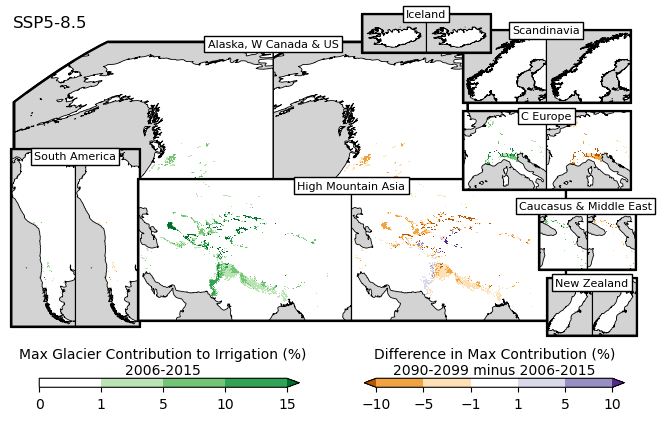

In [19]:
data1 = 100 * irrmax_2006_2015
data2 = 100 * irr_multigcm_med_dif_masked
lon = ds_qmax.longitude
lat = ds_qmax.latitude

# Define colormap and norm
bounds = [0, 1, 5, 10, 15]
colors_all = ['white', '#bae4b3', '#74c476', '#31a354', '#006d2c']  # GREENS
colors = colors_all[0:4]
cmap1 = mcolors.ListedColormap(colors)
cmap1.set_over(colors_all[4])
norm1 = mcolors.BoundaryNorm(bounds, cmap1.N)

# Difference colormap
# # cmap_dif = plt.get_cmap('RdYlBu')
# # norm_dif = Normalize(vmin=-20, vmax=20)
bounds_2 = [-10, -5, -1, 1, 5, 10]
colors_all_2 = ['#b35806', '#f1a340', '#fee0b6', 'white', '#d8daeb', '#998ec3', '#542788']
colors_2 = colors_all_2[1:6]
cmap2 = mcolors.ListedColormap(colors_2)
cmap2.set_over(colors_all_2[6])
cmap2.set_under(colors_all_2[0])
norm2 = mcolors.BoundaryNorm(bounds_2, cmap2.N)

# Filter data (plots underlying lakes, etc.)
data1[data1 <= bounds[1]] = np.nan
data2[(data2 >= bounds_2[2]) & (data2 <= bounds_2[3])] = np.nan


# Textbox properties
edgewidth=2.5
props = dict(boxstyle='square', facecolor='white', edgecolor='black', linewidth=1)
    

# ------ CREATE FIGURE ----- 
fig = plt.figure(figsize=(6.5, 6))

# ----- NORTH AMERICA -----
region_bounds = [-158,-120, 42, 75]
subplot_loc1 = [0.01, 0.5, 0.4, 0.4]
subplot_loc2 = [0.31, 0.5, 0.4, 0.4]
# Future
# ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2)
ax_NA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth, extraedge=True)
# Present
ax_NA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, 
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth, extraedge=True)
# Label
ax_NA1.text(1, 0.98, "Alaska, W Canada & US",
            transform=ax_NA1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)

# ----- SOUTH AMERICA -----
region_bounds = [-82, -65, -57, 13]
subplot_loc1 = [0.005, -0.01, 0.1, 1]
subplot_loc2 = [0.105, -0.01, 0.1, 1]
# Present
ax_SA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_SA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_SA2.text(1, 0.98, "South America",
            transform=ax_SA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# # ----- High Mountain Asia -----
region_bounds = [53, 108, 18, 55]
subplot_loc1 = [0.2, 0.295, 0.33, 0.35]
subplot_loc2 = [0.53, 0.295, 0.33, 0.35]
# Present
ax_HMA1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                           edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_HMA2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                           edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_HMA2.text(1, 0.98, "High Mountain Asia",
            transform=ax_HMA1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- SCANDINAVIA -----
region_bounds = [4,23.5,57.5,72]
subplot_loc1 = [0.70, 0.70, 0.13, 0.15]
subplot_loc2 = [0.83, 0.70, 0.13, 0.15]
# Present
ax_S1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_S2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_S2.text(1, 0.98, "Scandinavia",
           transform=ax_S1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- Iceland -----
region_bounds = [-25,-13,62.5,68.7]
subplot_loc1 = [0.545, 0.78, 0.1, 0.1]
subplot_loc2 = [0.645, 0.78, 0.1, 0.1]
# Present
ax_I1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_I2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_I2.text(1, 0.98, "Iceland",
           transform=ax_I1.transAxes, fontsize=8, ha='center', va='center', bbox=props, zorder=20)


# ----- CENTRAL EUROPE -----
region_bounds = [-2,19,38.2,55]
subplot_loc1 = [0.70, 0.561, 0.13, 0.15]
subplot_loc2 = [0.83, 0.561, 0.13, 0.15]
# Present
ax_CE1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_CE2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_CE2.text(1, 0.98, "C Europe",
            transform=ax_CE1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)


# ----- CAUCASUS & Middle East -----
region_bounds = [36,51,30,49]
subplot_loc1 = [0.805, 0.435, 0.1, 0.1]
subplot_loc2 = [0.88, 0.435, 0.1, 0.1]
# Present
ax_C1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1,
                         edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_C2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2,
                         edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_C2.text(0.97, 0.99, "Caucasus & Middle East",
           transform=ax_C1.transAxes, fontsize=8, ha='center', va='bottom', bbox=props, zorder=20)


# ----- New Zealand -----
region_bounds = [167,175,-47,-39]
subplot_loc1 = [0.83, 0.325, 0.07, 0.1]
subplot_loc2 = [0.9, 0.325, 0.07, 0.1]
# change projection so New Zealand looks normal
projection_NZ = ccrs.TransverseMercator(central_longitude=173.0, central_latitude=0.0,
                                        false_easting=1600000, false_northing=10000000,
                                        scale_factor=0.9996, globe=ccrs.Globe(datum='WGS84', ellipse='GRS80'))
# Present
ax_NZ1, im1 = add_subplot(region_bounds, subplot_loc1, lon, lat, data1, cmap1, norm1, projection_map=projection_NZ,
                          edges2bold=("top","bottom","left"), edgewidth=edgewidth)
# Future
ax_NZ2, im2 = add_subplot(region_bounds, subplot_loc2, lon, lat, data2, cmap2, norm2, projection_map=projection_NZ,
                          edges2bold=("top","bottom","right"), edgewidth=edgewidth)
# Label
ax_NZ2.text(1, 0.98, "New Zealand",
            transform=ax_NZ1.transAxes, fontsize=8, ha='center', va='top', bbox=props, zorder=20)

# ----- ADD COLORBAR -----
cbar_ax = fig.add_axes([0.05, 0.24, 0.4, 0.015])
cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal', extend='max')
cbar.set_label('Max Glacier Contribution to Irrigation (%)\n2006-2015', fontsize=10, labelpad=-46)

cbar_ax2 = fig.add_axes([0.55, 0.24, 0.4, 0.015])
cbar2 = fig.colorbar(im2, cax=cbar_ax2, orientation='horizontal', extend='both')
cbar2.set_label('Difference in Max Contribution (%)\n2090-2099 minus 2006-2015', fontsize=10, labelpad=-46)

# ----- SSP Label -----
fig.text(0.01, 0.86, ssp_name_dict[ssp], fontsize=12, ha='left', va='top')


# Adjust layout to prevent overlap
fig.savefig(paper_fig_fp + 'maps-subregions-irr_dif-' + ssp + '.png', bbox_inches='tight', dpi=300)
plt.show()